# Trainer — entraînement des modèles

Le `Trainer` est **générique** : il entraîne n'importe quel objet qui hérite de `Module`
(`MLP`, `CNN`, ou un modèle perso). Il gère la boucle d'entraînement, les mini-batchs,
le learning rate adaptatif et l'enregistrement des pertes.

In [8]:
from NeuralNetworks import MLP, Trainer, losses, learnings
import torch

## Données d'exemple

On génère un problème de régression 1D : apprendre `y = sin(2πx)`.

In [9]:
torch.manual_seed(0)
inputs = torch.linspace(0, 1, 500).unsqueeze(1)   # [500, 1]
outputs = torch.sin(2 * torch.pi * inputs)        # [500, 1]

## Paramètres du Trainer

| Paramètre | Rôle |
|---|---|
| `net` (positionnel) | le modèle à entraîner (peut en prendre plusieurs) |
| `inputs` / `outputs` | tenseurs d'entraînement, première dim = nb d'échantillons (`outputs=None` → non supervisé) |
| `crit` | critère de loss (`"MSE"`, `"L1"`, `"CrossEntropy"`...), liste de critères, ou callable custom |
| `optim` | optimiseur (`"Adam"`, `"SGD"`, `"AdamW"`...) |
| `init_lr` / `final_lr` | learning rate de début et de fin |
| `batch_size` | taille des mini-batchs |
| `init_train_size` / `final_train_size` | fraction des données utilisée (monte progressivement, ex. 0.01 → 1.0) |

Le learning rate n'est pas fixe : il est **adapté automatiquement** à chaque époque en fonction des pertes récentes.

In [10]:
net = MLP(input_size=1, output_size=1, hidden_layers=[64, 64], norm="Tanh", name="SinNet")

In [11]:
trainer = Trainer(net,
                  inputs=inputs, outputs=outputs,
                  init_train_size=1.0, final_train_size=1.0,
                  crit="MSE", optim="Adam",
                  init_lr=1e-3, final_lr=1e-5,
                  batch_size=64)
trainer.train(200)

Training SinNet:   0%|          | 0/200 [00:00<?, ?epoch/s]

## Visualiser l'entraînement

Les pertes et learning rates sont stockés dans `net.losses` et `net.learnings`, et se tracent avec `losses(net)` et `learnings(net)`.

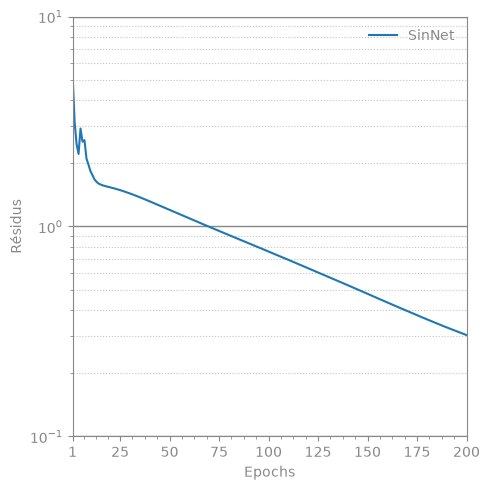

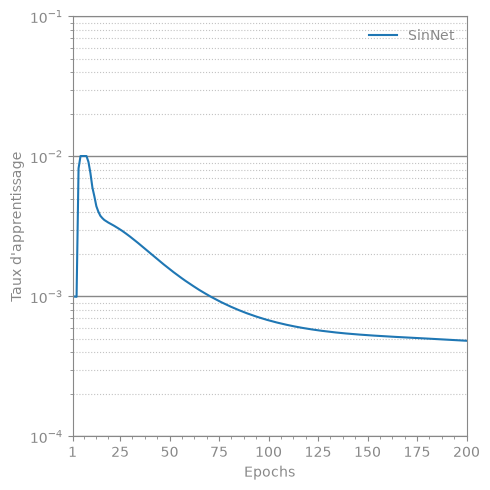

In [12]:
losses(net)
learnings(net)

## Vérifier le résultat

On compare la prédiction du réseau à la vraie fonction sur une grille fine.

In [13]:
x_test = torch.linspace(0, 1, 100).unsqueeze(1)
y_pred = net(x_test)
y_true = torch.sin(2 * torch.pi * x_test)
print("Erreur max :", (y_pred - y_true).abs().max().item())

Erreur max : 0.5164440274238586
